# Movie Information Extraction Agent using LangChain + Groq + TMDB API


In [1]:
import sys

print(sys.executable)

/Users/tarunya/codeWorld/agentic-ai-learning/movie-info-agent/.venv/bin/python


In [16]:
import os
from dotenv import load_dotenv
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

tmdb_session = requests.Session()
tmdb_session.mount(
    "https://",
    HTTPAdapter(
        max_retries=Retry(
            total=5,
            connect=3,
            read=2,
            backoff_factor=0.5,
            status_forcelist=[429, 500, 502, 503, 504],
            allowed_methods=["GET"],
        )
    ),
)

load_dotenv()


True

# fetch all the models

In [17]:
from groq import Groq

client = Groq()

models = client.models.list()

for model in models.data:
    print(model.id)

meta-llama/llama-prompt-guard-2-22m
qwen/qwen3.8-27b
openai/gpt-oss-safeguard-20b
allam-2-7b
whisper-large-v3-turbo
openai/gpt-oss-20b
canopylabs/orpheus-arabic-saudi
canopylabs/orpheus-v1-english
openai/gpt-oss-120b
whisper-large-v3
meta-llama/llama-prompt-guard-2-86m


# Structure to fetch a movie using TypedDict

In [18]:
from typing_extensions import TypedDict,Annotated
from langchain_groq import ChatGroq

class MovieRequest(TypedDict):
    title:Annotated[
        str,
        ...,
        'movie title'
    ]

    genres: Annotated[
        list[str],
        ...,
        "Genres explicitly mentioned by the user. Use an empty list if none."
    ]

# model instance
llm_model = ChatGroq(model="openai/gpt-oss-120b", temperature=0.2)

structured_model=llm_model.with_structured_output(MovieRequest,method="json_schema",strict=True)

In [19]:
user_input = """
Tell me about Avengers: Doomsday.
It is an action, adventure and science-fiction movie.
"""

extracted_movie=structured_model.invoke(user_input)

print(extracted_movie)

{'title': 'Avengers: Doomsday', 'genres': ['action', 'adventure', 'science-fiction']}


# Integrated TMDB API

In [20]:
TMDB_TOKEN = os.getenv("TMDB_READ_ACCESS_TOKEN")
headers = {"accept": "application/json", "Authorization": f"Bearer {TMDB_TOKEN}"}

# Check whether token exists 
print("Token exists:", bool(TMDB_TOKEN))
print("Token length:", len(TMDB_TOKEN) if TMDB_TOKEN else 0)

Token exists: True
Token length: 239


# Function to search for a movie

In [21]:
def search_movie(title: str):

    if not TMDB_TOKEN:
        raise ValueError("TMDB access token is missing.")

    url = "https://api.themoviedb.org/3/search/movie"

    params = {"query": title, "language": "en-US", "include_adult": False}

    response = tmdb_session.get(url, headers=headers, params=params, timeout=20)

    if response.status_code == 401:
        raise ValueError(
            "TMDB authentication failed. " "Check your API Read Access Token."
        )

    response.raise_for_status()

    data = response.json()

    if not data.get("results"):
        return None

    return data["results"][0]

# Retrieve official movie details


In [22]:
def get_movie_details(movie_id:int):
    url = f"https://api.themoviedb.org/3/movie/{movie_id}"
    
    params={
        'language':"en-us"
    }
    response=tmdb_session.get(
        url,
        params=params,
        headers=headers,
        timeout=20
    )
    
    response.raise_for_status()
    
    return response.json()

# Calculate release status using Python


In [23]:
from datetime import date

def calculate_release_status(release_date):
    if not release_date:
        return None
    
    release=date.fromisoformat(release_date)
    
    return release <=date.today()

# Movie info Agent

In [24]:
def movie_info_agent(user_input:str):
    
    #  Extract movie information using LLM
    extracted=structured_model.invoke(user_input)
    
    title=extracted["title"]
    
    # search TMDB
    search_result=search_movie(title=title)
    
    if search_result is None:
        return f"No movie found for :{title}"
    
    # get movie offical details
    details=get_movie_details(search_result['id'])
    
    # extract factual info
    release_date=details.get("release_date") or None
    
    vote_count=details.get("vote_count",0)
    
    rating=(
        details.get("vote_average")
        if vote_count>0
        else None  
    )
    
    # calculate release status
    is_released=calculate_release_status(release_date)
    
    # return final movie info --> structured response
    return {"title": details["title"],
        "genres": [genre["name"] for genre in details["genres"]],
        "user_mentioned_genres": extracted["genres"],
        "rating": rating,
        "vote_count": vote_count,
        "release_date": release_date,
        "is_released": is_released,
        "tmdb_id": details["id"]
    }

In [25]:
from langchain.tools import tool
import json
@ tool 
def search_tmdb_movie(title:str)->str:
    """
    Search for a movie on TMDB using its title.
    Returns the movie ID, title, release date and overview.
    """

    result=search_movie(title)

    if result is None:
        return f"No movie found for {title}"
    movie = {
        "id": result["id"],
        "title": result["title"],
        "release_date": result.get("release_date"),
        "overview": result.get("overview"),
    }
    
    return json.dumps(movie)

In [26]:
@ tool
def get_tmdb_movie_details(movie_id:int)->str:
    """
    Get official movie information from TMDB using its movie ID.
    Returns genres, rating, vote count and release date.
    """

    details=get_movie_details(movie_id)

    movie = {
        "id": details["id"],
        "title": details["title"],
        "genres": [genre["name"] for genre in details.get("genres", [])],
        "rating": details.get("vote_average"),
        "vote_count": details.get("vote_count"),
        "release_date": details.get("release_date"),
        "overview": details.get("overview"),
    }
    
    return json.dumps(movie)

# tools list

In [27]:
tools = [search_tmdb_movie, get_tmdb_movie_details]

# Test tools

In [37]:
title="spiderman"
search_tmdb_movie.invoke({'title':title})

'{"id": 969681, "title": "Spider-Man: Brand New Day", "release_date": "2026-07-29", "overview": "Fighting crime full-time as Spider-Man in a world that doesn\'t remember him\\u2014and the pressure of seeing his old friends move on without him\\u2014sparks a change in Peter Parker he may not have the power to control. But that transformation might also be the only thing that can stop a shocking new threat to the city and those he loves - a powerful villain no one can even see."}'

In [28]:
YOUR_MOVIE_ID = 1003596
get_tmdb_movie_details.invoke({"movie_id": YOUR_MOVIE_ID})

'{"id": 1003596, "title": "Avengers: Doomsday", "genres": ["Science Fiction", "Action", "Adventure"], "rating": 0.0, "vote_count": 0, "release_date": "2026-12-16", "overview": "Beloved heroes from three distinct universes are set on a deadly collision course and face an existential threat unlike anything they\'ve ever encountered."}'

# create agent

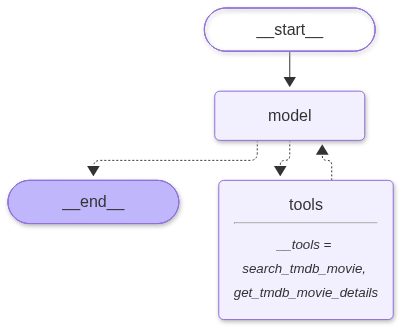

In [29]:
from langchain.agents import create_agent

agent = create_agent(
    model=llm_model,
    tools=tools,
    system_prompt="""
    You are a movie information assistant.

    Your responsibilities:

    1. Understand the user's movie-related question.
    2. Use search_tmdb_movie to find the requested movie.
    3. Use get_tmdb_movie_details to retrieve official information.
    4. Never invent movie ratings, genres or release dates.
    5. If a movie cannot be found, clearly tell the user.
    6. Provide a clear and informative response.
    """
)
agent

In [30]:
response = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "Tell me about a movie called XYZ12345.",
            }
        ]
    }
)
response['messages'][-1].content



'I’m sorry, but I couldn’t find any movie titled **“XYZ12345.”** If you have another title (or more details such as a year, director, or actor), feel free to let me know and I’ll be happy to look it up for you!'

In [31]:
for message in response['messages']:
    print(f"\n{message}")


content='Tell me about a movie called XYZ12345.' additional_kwargs={} response_metadata={} id='4854ece1-d1d0-461f-a3a5-a5a835a3415e'

content='' additional_kwargs={'reasoning_content': 'User asks about a movie called "XYZ12345". Likely not a real movie. We need to search TMDB. Use search_tmdb_movie with title "XYZ12345".', 'tool_calls': [{'id': 'fc_ae331947-8fa7-4a26-911d-49f4f9008740', 'function': {'arguments': '{"title":"XYZ12345"}', 'name': 'search_tmdb_movie'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 69, 'prompt_tokens': 288, 'total_tokens': 357, 'completion_time': 0.149007982, 'completion_tokens_details': {'reasoning_tokens': 38}, 'prompt_time': 0.034978919, 'prompt_tokens_details': None, 'queue_time': 0.060505818, 'total_time': 0.183986901}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_7a4ab09ae4', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a1d1ad-fb

In [32]:
for message in response["messages"]:

    print("\nMessage type:", type(message).__name__)
    print("Content:", message.content)

    if hasattr(message, "tool_calls") and message.tool_calls:
        print("Tool calls:", message.tool_calls)

    if hasattr(message, "tool_call_id"):
        print("Tool call ID:", message.tool_call_id)


Message type: HumanMessage
Content: Tell me about a movie called XYZ12345.

Message type: AIMessage
Content: 
Tool calls: [{'name': 'search_tmdb_movie', 'args': {'title': 'XYZ12345'}, 'id': 'fc_ae331947-8fa7-4a26-911d-49f4f9008740', 'type': 'tool_call'}]

Message type: ToolMessage
Content: No movie found for XYZ12345
Tool call ID: fc_ae331947-8fa7-4a26-911d-49f4f9008740

Message type: AIMessage
Content: I’m sorry, but I couldn’t find any movie titled **“XYZ12345.”** If you have another title (or more details such as a year, director, or actor), feel free to let me know and I’ll be happy to look it up for you!


# using stream()

In [33]:
for chunk in agent.stream(
    {
            "messages": [
                {
                    "role": "user",
                    "content": "Tell me about a movie called XYZ12345.",
                }
            ]
    },
    stream_mode="updates"
):
    print(chunk)
    


{'model': {'messages': [AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks about a movie called "XYZ12345". Likely not a real movie. Need to search TMDB. Use search_tmdb_movie with title "XYZ12345".', 'tool_calls': [{'id': 'fc_13704bcf-20db-4c73-a903-553382c589d1', 'function': {'arguments': '{"title":"XYZ12345"}', 'name': 'search_tmdb_movie'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 68, 'prompt_tokens': 288, 'total_tokens': 356, 'completion_time': 0.146226482, 'completion_tokens_details': {'reasoning_tokens': 37}, 'prompt_time': 0.013396253, 'prompt_tokens_details': None, 'queue_time': 0.321510247, 'total_time': 0.159622735}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_64b2f1c926', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1d1ad-ff11-725c-aa0c-1a66aa08c77c-0', tool_calls=[{'name': 'search_tmdb_movie', 'args': {'title': 'XYZ12345'}

In [34]:
from langchain.messages import AIMessage

for chunk in agent.stream(
    {
        "messages": [
            {
                "role": "user",
                "content": "Find Interstellar and tell me its rating.",
            }
        ]
    },
    stream_mode="messages",
):
    print(chunk)

(AIMessageChunk(content='', additional_kwargs={}, response_metadata={'model_provider': 'groq'}, id='lc_run--01a1d1ae-037c-741d-a141-ed54ab3138e5', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[]), {'ls_integration': 'langchain_chat_model', 'langgraph_step': 1, 'langgraph_node': 'model', 'langgraph_triggers': ('branch:to:model',), 'langgraph_path': ('__pregel_pull', 'model'), 'langgraph_checkpoint_ns': 'model:57a0dece-4825-9600-c36f-4e77e71be4bf', 'checkpoint_ns': 'model:57a0dece-4825-9600-c36f-4e77e71be4bf', 'ls_provider': 'groq', 'ls_model_name': 'openai/gpt-oss-120b', 'ls_model_type': 'chat', 'ls_temperature': 0.2, 'lc_versions': {'langchain-core': '1.8.0', 'langchain': '1.5.0'}})
(AIMessageChunk(content='', additional_kwargs={'reasoning_content': 'We'}, response_metadata={'model_provider': 'groq'}, id='lc_run--01a1d1ae-037c-741d-a141-ed54ab3138e5', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[]), {'ls_integration': 'langchain_chat_model', 'langgraph_step': 1, 'l

In [35]:
result=agent.invoke({
    "messages":[
        {
            'role':'user',
            'content':'Find The Dark Knight and give me its official genres, release date, rating and vote count.'
        }
    ]
})

result


{'messages': [HumanMessage(content='Find The Dark Knight and give me its official genres, release date, rating and vote count.', additional_kwargs={}, response_metadata={}, id='2fe68f2d-1737-44d2-8026-8c51096ef65a'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to search for "The Dark Knight". Use search_tmdb_movie. Then get details.', 'tool_calls': [{'id': 'fc_00489dfa-f4e7-44e9-b6dc-6047af058e1d', 'function': {'arguments': '{"title":"The Dark Knight"}', 'name': 'search_tmdb_movie'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 52, 'prompt_tokens': 553, 'total_tokens': 605, 'completion_time': 0.109800683, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.001887233, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.049604996, 'total_time': 0.111687916}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_420c059a6a', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', '